# LLM Hallucination Evaluation

Comparing two open-source LLMs on SQuAD 2.0 — how well they answer when the context has the info, and whether they make stuff up when it doesn't.

In [1]:
!pip install -q transformers datasets accelerate sentence-transformers pandas matplotlib scikit-learn

In [2]:
import time
import random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer

random.seed(42)

## Load the data

In [3]:
dataset = load_dataset("rajpurkar/squad_v2")
validation = dataset["validation"]

print(len(validation))
validation[0]

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

11873


{'id': '56ddde6b9a695914005b9628',
 'title': 'Normans',
 'context': 'The Normans (Norman: Nourmands; French: Normands; Latin: Normanni) were the people who in the 10th and 11th centuries gave their name to Normandy, a region in France. They were descended from Norse ("Norman" comes from "Norseman") raiders and pirates from Denmark, Iceland and Norway who, under their leader Rollo, agreed to swear fealty to King Charles III of West Francia. Through generations of assimilation and mixing with the native Frankish and Roman-Gaulish populations, their descendants would gradually merge with the Carolingian-based cultures of West Francia. The distinct cultural and ethnic identity of the Normans emerged initially in the first half of the 10th century, and it continued to evolve over the succeeding centuries.',
 'question': 'In what country is Normandy located?',
 'answers': {'text': ['France', 'France', 'France', 'France'],
  'answer_start': [159, 159, 159, 159]}}

In [4]:
answerable = [x for x in validation if len(x["answers"]["text"]) > 0]
unanswerable = [x for x in validation if len(x["answers"]["text"]) == 0]

print(len(answerable), len(unanswerable))

5928 5945


In [5]:
answerable_sample = random.sample(answerable, 100)
unanswerable_sample = random.sample(unanswerable, 100)

examples = answerable_sample + unanswerable_sample
random.shuffle(examples)

len(examples)

200

## Load a model


In [6]:
model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto"
)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## The prompt + generation function

In [7]:
PROMPT_TEMPLATE = """You are a question-answering system.

Answer the question using ONLY information explicitly stated in the provided context.

Rules:
1. Return only the short answer. Do not provide explanations.
2. Do not use outside knowledge.
3. If the answer cannot be determined from the context, return exactly:

INSUFFICIENT_CONTEXT

Context:
{context}

Question:
{question}

Answer:"""


def generate_answer(model, tokenizer, context, question):
    prompt = PROMPT_TEMPLATE.format(context=context, question=question)

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=2048).to(model.device)

    start = time.time()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=40, do_sample=False)
    latency = time.time() - start

    generated = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return generated.strip(), latency

## Full run — Model A




In [9]:
results = []

for example in examples:
    answer, latency = generate_answer(model, tokenizer, example["context"], example["question"])
    ground_truth = example["answers"]["text"][0] if example["answers"]["text"] else None

    results.append({
        "model": model_name,
        "question": example["question"],
        "ground_truth": ground_truth,
        "answerable": ground_truth is not None,
        "model_answer": answer,
        "latency": latency
    })

df_a = pd.DataFrame(results)
len(df_a)

200

In [10]:
df_a.to_csv("model_a_results.csv", index=False)
df_a.head()

,model,question,ground_truth,answerable,model_answer,latency
0,Qwen/Qwen2.5-1.5B-Instruct,Where did Korea border Kublai's territory?,northeast,True,Korea bordered Kublai's territory along its no...,1.510729
1,Qwen/Qwen2.5-1.5B-Instruct,What is Fe2O?,None,False,Iron(III) oxide,0.242067
2,Qwen/Qwen2.5-1.5B-Instruct,What was Apple Talk,a proprietary suite of networking protocols de...,True,A proprietary suite of networking protocols de...,1.535611
3,Qwen/Qwen2.5-1.5B-Instruct,What was the very first television station to ...,KMJ-TV,True,KMJ-TV\nThe very first television station to b...,1.591926
4,Qwen/Qwen2.5-1.5B-Instruct,What must the adoption of laws which will have...,a proper legal basis,True,A proper legal basis.,0.262786


Swap `model_name` for model B, reload the model, rerun the 10-example check with the same frozen prompt, then rerun this same full-run cell (renaming `df_a` to `df_b` and the CSV filename) before moving on to scoring.

## Evaluation — Model A

### Text normalization + Exact Match / F1

Standard SQuAD-style normalization: lowercase, drop punctuation, drop articles, collapse whitespace. Same normalization used on both the model answer and the ground truth before comparing.

In [11]:
import re
import string


def normalize_answer(s):
    s = s.lower()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = "".join(ch for ch in s if ch not in string.punctuation)
    s = " ".join(s.split())
    return s


def exact_match(pred, gold):
    return int(normalize_answer(pred) == normalize_answer(gold))


def f1_score(pred, gold):
    pred_tokens = normalize_answer(pred).split()
    gold_tokens = normalize_answer(gold).split()

    if len(pred_tokens) == 0 or len(gold_tokens) == 0:
        return int(pred_tokens == gold_tokens)

    common = set(pred_tokens) & set(gold_tokens)
    num_common = sum(min(pred_tokens.count(t), gold_tokens.count(t)) for t in common)

    if num_common == 0:
        return 0.0

    precision = num_common / len(pred_tokens)
    recall = num_common / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)

In [12]:
answerable_a = df_a[df_a["answerable"]].copy()
unanswerable_a = df_a[~df_a["answerable"]].copy()

answerable_a["em"] = answerable_a.apply(lambda r: exact_match(r["model_answer"], r["ground_truth"]), axis=1)
answerable_a["f1"] = answerable_a.apply(lambda r: f1_score(r["model_answer"], r["ground_truth"]), axis=1)

em_a = answerable_a["em"].mean()
f1_a = answerable_a["f1"].mean()

print(f"exact match: {em_a:.3f}")
print(f"f1: {f1_a:.3f}")

exact match: 0.300
f1: 0.537


### Semantic similarity

EM/F1 punish paraphrases ("a proper legal basis" vs "proper legal basis for this"). Cosine similarity between embeddings gives a softer, more forgiving read on the answerable set.

In [13]:
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

pred_embeddings = embedding_model.encode(answerable_a["model_answer"].tolist())
gold_embeddings = embedding_model.encode(answerable_a["ground_truth"].tolist())

from sklearn.metrics.pairwise import cosine_similarity

sims = [cosine_similarity([p], [g])[0][0] for p, g in zip(pred_embeddings, gold_embeddings)]
answerable_a["semantic_similarity"] = sims

semantic_sim_a = answerable_a["semantic_similarity"].mean()
print(f"semantic similarity: {semantic_sim_a:.3f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

semantic similarity: 0.679


### Refusal rate / hallucination rate

On the unanswerable set, a correct refusal means the model's answer contains `INSUFFICIENT_CONTEXT`. Anything else counts as a hallucination — including answers that happen to be factually true, since the model wasn't grounded in the context.

In [14]:
unanswerable_a["refused"] = unanswerable_a["model_answer"].str.contains("INSUFFICIENT_CONTEXT", case=False)

refusal_rate_a = unanswerable_a["refused"].mean()
hallucination_rate_a = 1 - refusal_rate_a

print(f"correct refusal rate: {refusal_rate_a:.3f}")
print(f"hallucination rate: {hallucination_rate_a:.3f}")

correct refusal rate: 0.280
hallucination rate: 0.720


### Summary

In [15]:
summary_a = {
    "model": model_name,
    "exact_match": em_a,
    "f1": f1_a,
    "semantic_similarity": semantic_sim_a,
    "refusal_rate": refusal_rate_a,
    "hallucination_rate": hallucination_rate_a,
    "avg_latency": df_a["latency"].mean()
}

summary_a

{'model': 'Qwen/Qwen2.5-1.5B-Instruct',
 'exact_match': np.float64(0.3),
 'f1': np.float64(0.5368446138915174),
 'semantic_similarity': np.float32(0.6790692),
 'refusal_rate': np.float64(0.28),
 'hallucination_rate': np.float64(0.72),
 'avg_latency': np.float64(0.5946163642406463)}

## Model B — Mistral-7B-Instruct-v0.3

Mistral is gated on the Hub, so you need to accept the license on the [model page](https://huggingface.co/mistralai/Mistral-7B-Instruct-v0.3) and authenticate below. It's also a much bigger model than Qwen 1.5B, so free up Model A's memory first.

In [16]:
del model, tokenizer
torch.cuda.empty_cache()

In [18]:
from huggingface_hub import notebook_login

notebook_login()

In [19]:
model_name = "mistralai/Mistral-7B-Instruct-v0.3"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto"
)

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Same frozen prompt, same 10-example check — just confirming this model loads and generates before committing to the full run.

In [20]:
for example in examples[:10]:
    answer, latency = generate_answer(model, tokenizer, example["context"], example["question"])
    truth = example["answers"]["text"][0] if example["answers"]["text"] else "(unanswerable)"

    print("Q:", example["question"])
    print("truth:", truth)
    print("model:", answer)
    print(f"{latency:.2f}s")
    print("-" * 60)

Q: Where did Korea border Kublai's territory?
truth: northeast
model: Northeast border
2.42s
------------------------------------------------------------
Q: What is Fe2O?
truth: (unanswerable)
model: Iron(III) oxide
3.39s
------------------------------------------------------------
Q: What was Apple Talk 
truth: a proprietary suite of networking protocols developed by Apple Inc. in 1985
model: AppleTalk was a proprietary suite of networking protocols developed by Apple Inc. for Apple Macintosh computers.
9.31s
------------------------------------------------------------
Q: What was the very first television station to broadcast in Fresno?
truth: KMJ-TV
model: KMJ-TV
2.69s
------------------------------------------------------------
Q: What must the adoption of laws which will have legal effect in the EU have?
truth: a proper legal basis
model: A proper legal basis.
2.61s
------------------------------------------------------------
Q: What was believed to be the cause of devastation to 

### Full run — Model B

In [21]:
results = []

for example in examples:
    answer, latency = generate_answer(model, tokenizer, example["context"], example["question"])
    ground_truth = example["answers"]["text"][0] if example["answers"]["text"] else None

    results.append({
        "model": model_name,
        "question": example["question"],
        "ground_truth": ground_truth,
        "answerable": ground_truth is not None,
        "model_answer": answer,
        "latency": latency
    })

df_b = pd.DataFrame(results)
len(df_b)

200

In [22]:
df_b.to_csv("model_b_results.csv", index=False)
df_b.head()

,model,question,ground_truth,answerable,model_answer,latency
0,mistralai/Mistral-7B-Instruct-v0.3,Where did Korea border Kublai's territory?,northeast,True,Northeast border,2.242643
1,mistralai/Mistral-7B-Instruct-v0.3,What is Fe2O?,None,False,Iron(III) oxide,3.256458
2,mistralai/Mistral-7B-Instruct-v0.3,What was Apple Talk,a proprietary suite of networking protocols de...,True,AppleTalk was a proprietary suite of networkin...,9.389137
3,mistralai/Mistral-7B-Instruct-v0.3,What was the very first television station to ...,KMJ-TV,True,KMJ-TV,2.614260
4,mistralai/Mistral-7B-Instruct-v0.3,What must the adoption of laws which will have...,a proper legal basis,True,A proper legal basis.,2.745691


### Evaluation — Model B

Same metrics, same code path as Model A.

In [23]:
answerable_b = df_b[df_b["answerable"]].copy()
unanswerable_b = df_b[~df_b["answerable"]].copy()

answerable_b["em"] = answerable_b.apply(lambda r: exact_match(r["model_answer"], r["ground_truth"]), axis=1)
answerable_b["f1"] = answerable_b.apply(lambda r: f1_score(r["model_answer"], r["ground_truth"]), axis=1)

em_b = answerable_b["em"].mean()
f1_b = answerable_b["f1"].mean()

pred_embeddings_b = embedding_model.encode(answerable_b["model_answer"].tolist())
gold_embeddings_b = embedding_model.encode(answerable_b["ground_truth"].tolist())
sims_b = [cosine_similarity([p], [g])[0][0] for p, g in zip(pred_embeddings_b, gold_embeddings_b)]
answerable_b["semantic_similarity"] = sims_b
semantic_sim_b = answerable_b["semantic_similarity"].mean()

unanswerable_b["refused"] = unanswerable_b["model_answer"].str.contains("INSUFFICIENT_CONTEXT", case=False)
refusal_rate_b = unanswerable_b["refused"].mean()
hallucination_rate_b = 1 - refusal_rate_b

summary_b = {
    "model": model_name,
    "exact_match": em_b,
    "f1": f1_b,
    "semantic_similarity": semantic_sim_b,
    "refusal_rate": refusal_rate_b,
    "hallucination_rate": hallucination_rate_b,
    "avg_latency": df_b["latency"].mean()
}

summary_b

{'model': 'mistralai/Mistral-7B-Instruct-v0.3',
 'exact_match': np.float64(0.4),
 'f1': np.float64(0.6462582084460143),
 'semantic_similarity': np.float32(0.75269395),
 'refusal_rate': np.float64(0.56),
 'hallucination_rate': np.float64(0.43999999999999995),
 'avg_latency': np.float64(4.691714639663696)}

### Model A vs Model B

In [24]:
comparison = pd.DataFrame([summary_a, summary_b]).set_index("model")
comparison

,exact_match,f1,semantic_similarity,refusal_rate,hallucination_rate,avg_latency
model,,,,,,
Qwen/Qwen2.5-1.5B-Instruct,0.3,0.536845,0.679069,0.28,0.72,0.594616
mistralai/Mistral-7B-Instruct-v0.3,0.4,0.646258,0.752694,0.56,0.44,4.691715


## Visualizations

Four charts off the comparison table: hallucination rate, F1, semantic similarity, latency. Saved to `figures/` for the README.

In [25]:
import os

os.makedirs("figures", exist_ok=True)

models = comparison.index.tolist()
colors = ["#4C72B0", "#DD8452"]

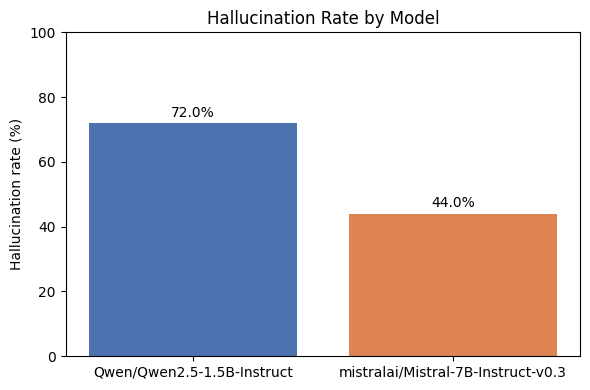

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(models, comparison["hallucination_rate"] * 100, color=colors)
ax.set_ylabel("Hallucination rate (%)")
ax.set_title("Hallucination Rate by Model")
ax.set_ylim(0, 100)

for i, v in enumerate(comparison["hallucination_rate"] * 100):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("figures/hallucination_rate.png", dpi=150)
plt.show()

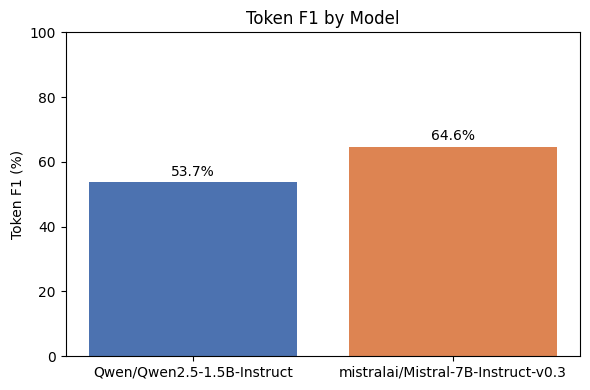

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(models, comparison["f1"] * 100, color=colors)
ax.set_ylabel("Token F1 (%)")
ax.set_title("Token F1 by Model")
ax.set_ylim(0, 100)

for i, v in enumerate(comparison["f1"] * 100):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("figures/f1_scores.png", dpi=150)
plt.show()

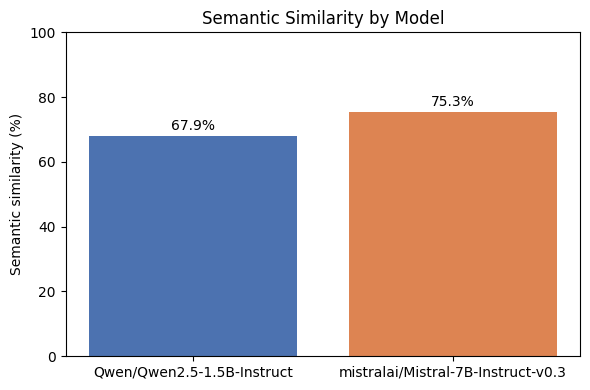

In [28]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(models, comparison["semantic_similarity"] * 100, color=colors)
ax.set_ylabel("Semantic similarity (%)")
ax.set_title("Semantic Similarity by Model")
ax.set_ylim(0, 100)

for i, v in enumerate(comparison["semantic_similarity"] * 100):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("figures/semantic_similarity.png", dpi=150)
plt.show()

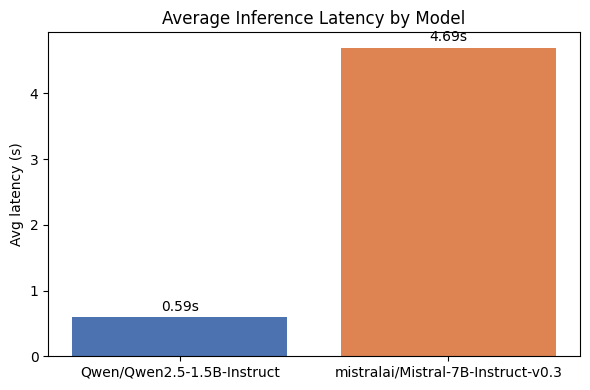

In [29]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(models, comparison["avg_latency"], color=colors)
ax.set_ylabel("Avg latency (s)")
ax.set_title("Average Inference Latency by Model")

for i, v in enumerate(comparison["avg_latency"]):
    ax.text(i, v + 0.1, f"{v:.2f}s", ha="center")

plt.tight_layout()
plt.savefig("figures/latency.png", dpi=150)
plt.show()

## Qualitative Hallucination Analysis

To better understand the models' behavior, we examine unanswerable questions where one model correctly refused to answer while the other generated an unsupported response.

In [38]:
def is_refusal(answer):
    answer = str(answer).lower().replace("_", " ").strip()
    return "insufficient context" in answer

In [39]:
# Keep only unanswerable examples
qa = df_a[~df_a["answerable"]][["question", "model_answer"]].copy()
qb = df_b[~df_b["answerable"]][["question", "model_answer"]].copy()

qa = qa.rename(columns={"model_answer": "qwen_answer"})
qb = qb.rename(columns={"model_answer": "mistral_answer"})

qualitative = qa.merge(qb, on="question")

qualitative["qwen_refused"] = qualitative["qwen_answer"].apply(is_refusal)
qualitative["mistral_refused"] = qualitative["mistral_answer"].apply(is_refusal)

qualitative.head()

,question,qwen_answer,mistral_answer,qwen_refused,mistral_refused
0,What is Fe2O?,Iron(III) oxide,Iron(III) oxide,False,False
1,Besides the analytic property of Goldbach's co...,Algebraic,Algebraic aspects of numbers.,False,False
2,What alternative to ARPANET was developed?,The CYCLADES packet switching network was deve...,CYCLADES packet switching network,False,False
3,What was the purpose of the suite developed in...,A suite of networking protocols,The purpose of the suite developed in 1985 was...,False,False
4,What is operated by Academic Colleges Group in...,St Dominic's College,INSUFFICIENT_CONTEXT (No information about Aca...,False,True


In [40]:
# Qwen hallucinated, Mistral correctly refused
qwen_hallucinated = qualitative[
    (~qualitative["qwen_refused"]) &
    (qualitative["mistral_refused"])
]

# Mistral hallucinated, Qwen correctly refused
mistral_hallucinated = qualitative[
    (qualitative["qwen_refused"]) &
    (~qualitative["mistral_refused"])
]

print("Qwen hallucinated / Mistral refused:", len(qwen_hallucinated))
print("Mistral hallucinated / Qwen refused:", len(mistral_hallucinated))

Qwen hallucinated / Mistral refused: 23
Mistral hallucinated / Qwen refused: 10


In [41]:
qwen_hallucinated[
    ["question", "qwen_answer", "mistral_answer"]
].head(5)

,question,qwen_answer,mistral_answer
4,What is operated by Academic Colleges Group in...,St Dominic's College,INSUFFICIENT_CONTEXT (No information about Aca...
7,When was the Model United Nations team ranked ...,2014-2015\nThe Model United Nations team was r...,INSUFFICIENT_CONTEXT (The context only mention...
16,When the Rhine took a right turn what did it c...,The Channel River\nThis answer is derived dire...,INSUFFICIENT_CONTEXT (The context does not pro...
22,Who was Ogedei's husband?,Töregene Khatun,INSUFFICIENT_CONTEXT
25,How many homes did the Pacific Improvement Cor...,267 homes.,INSUFFICIENT_CONTEXT


In [42]:
mistral_hallucinated[
    ["question", "qwen_answer", "mistral_answer"]
].head(5)

,question,qwen_answer,mistral_answer
12,What force is weaker than gravity over short d...,Insufficient Context,The weak force
23,What is the immune system unable to distinguis...,INSUFFICIENT_CONTEXT,Pathogens
24,Trotsky thought what was not needed for a true...,Sufficient context is lacking to determine wha...,Trotsky believed that the revolution could onl...
27,What has having an EU Citizenship decreased?,INSUFFICIENT_CONTEXT,Access to higher education and other forms of ...
31,In what direction does the river system extend?,Insufficient Context\nInsufficient Context,East-west


In [45]:
print("FINAL RESULTS")
print("=" * 50)

print("\nQwen2.5-1.5B-Instruct")
print(f"Exact Match: {summary_a['exact_match']:.1%}")
print(f"Token F1: {summary_a['f1']:.1%}")
print(f"Semantic Similarity: {summary_a['semantic_similarity']:.1%}")
print(f"Refusal Accuracy: {refusal_rate_a:.1%}")
print(f"Hallucination Rate: {hallucination_rate_a:.1%}")
print(f"Average Latency: {summary_a['avg_latency']:.2f} s")

print("\nMistral-7B-Instruct-v0.3")
print(f"Exact Match: {summary_b['exact_match']:.1%}")
print(f"Token F1: {summary_b['f1']:.1%}")
print(f"Semantic Similarity: {summary_b['semantic_similarity']:.1%}")
print(f"Refusal Accuracy: {refusal_rate_b:.1%}")
print(f"Hallucination Rate: {hallucination_rate_b:.1%}")
print(f"Average Latency: {summary_b['avg_latency']:.2f} s")

print("\nQUALITATIVE COMPARISON")
print("Qwen hallucinated / Mistral refused:", len(qwen_hallucinated))
print("Mistral hallucinated / Qwen refused:", len(mistral_hallucinated))

FINAL RESULTS

Qwen2.5-1.5B-Instruct
Exact Match: 30.0%
Token F1: 53.7%
Semantic Similarity: 67.9%
Refusal Accuracy: 28.0%
Hallucination Rate: 72.0%
Average Latency: 0.59 s

Mistral-7B-Instruct-v0.3
Exact Match: 40.0%
Token F1: 64.6%
Semantic Similarity: 75.3%
Refusal Accuracy: 56.0%
Hallucination Rate: 44.0%
Average Latency: 4.69 s

QUALITATIVE COMPARISON
Qwen hallucinated / Mistral refused: 23
Mistral hallucinated / Qwen refused: 10


In [46]:
comparison.to_csv("final_model_comparison.csv", index=False)

## Conclusion

This project evaluated Qwen2.5-1.5B-Instruct and Mistral-7B-Instruct-v0.3 on context-grounded question answering using a balanced sample of 200 examples from SQuAD 2.0, including 100 answerable and 100 unanswerable questions.

Mistral achieved stronger overall answer quality, with an Exact Match score of 40.0%, Token F1 of 64.6%, and semantic similarity of 75.3%, compared with 30.0%, 53.7%, and 67.9% for Qwen.

The largest difference appeared on unanswerable questions. Mistral correctly refused 56.0% of these questions, resulting in a 44.0% hallucination rate. Qwen correctly refused only 28.0%, resulting in a 72.0% hallucination rate. The qualitative analysis showed a similar pattern: there were 23 cases where Qwen generated an unsupported answer while Mistral refused, compared with 10 cases where Mistral hallucinated while Qwen refused.

However, Qwen was substantially faster in this experimental setup, with an average inference latency of 0.59 seconds compared with 4.69 seconds for Mistral.

Overall, the results demonstrate a trade-off between efficiency and reliability. Mistral provided stronger contextual grounding and answer quality, while Qwen offered significantly faster inference.

### Limitations

- The evaluation used a sample of 200 examples from SQuAD 2.0 rather than the complete dataset.
- Only two open-source language models were evaluated.
- The models differ significantly in size (1.5B vs. 7B parameters), so the comparison is not intended to isolate model architecture alone.
- Latency measurements reflect the specific Google Colab runtime and model-loading configuration used in this experiment.
- Hallucination was defined as generating an answer for an unanswerable question instead of refusing based on the provided context.
- Exact Match can penalize answers that are semantically correct but phrased differently, which is why Token F1 and semantic similarity were also included.